In [2]:
# ==================================================
# Population-PK-Modeling-and-Simulation
# PROJECT 1: ONE-COMPARTMENT PK DATA EXPLORATION
# ==================================================

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# STEP 1: Upload PK1 dataset
print("Please upload your PK1 dataset")

uploaded = files.upload()

# STEP 2: Read the uploaded CSV file
filename = list(uploaded.keys())[0]
pk1 = pd.read_csv(filename)

# STEP 3: Display the first 10 rows
print("\nFIRST 10 ROWS OF PK1")
display(pk1.head(10))

# STEP 4: Display column names
print("\nDATASET VARIABLES")
print(pk1.columns.tolist())

# STEP 5: Display dataset dimensions
print("\nDATASET DIMENSIONS")
print("Rows:", pk1.shape[0])
print("Columns:", pk1.shape[1])

# STEP 6: Display summary statistics
print("\nSUMMARY STATISTICS")
display(pk1.describe())

print("\nPK1 dataset successfully uploaded!")

Please upload your PK1 dataset


Saving Bolus_1CPT.csv to Bolus_1CPT (1).csv

FIRST 10 ROWS OF PK1


,ID,TIME,DV,LNDV,MDV,AMT,EVID,DOSE,V,CL,SS,II,SD,CMT
0,1,0.00,0.0,0.0000,1,60000,1,60000,65.14,4.07,99,0,1,1
1,1,0.25,1126.1,7.0265,0,0,0,60000,65.14,4.07,99,0,1,1
2,1,0.50,869.9,6.7683,0,0,0,60000,65.14,4.07,99,0,1,1
3,1,0.75,883.6,6.7840,0,0,0,60000,65.14,4.07,99,0,1,1
4,1,1.00,1244.0,7.1260,0,0,0,60000,65.14,4.07,99,0,1,1
5,1,1.50,995.2,6.9029,0,0,0,60000,65.14,4.07,99,0,1,1
6,1,2.00,946.4,6.8526,0,0,0,60000,65.14,4.07,99,0,1,1
7,1,2.50,589.2,6.3787,0,0,0,60000,65.14,4.07,99,0,1,1
8,1,3.00,754.4,6.6258,0,0,0,60000,65.14,4.07,99,0,1,1
9,1,4.00,1060.8,6.9667,0,0,0,60000,65.14,4.07,99,0,1,1



DATASET VARIABLES
['ID', 'TIME', 'DV', 'LNDV', 'MDV', 'AMT', 'EVID', 'DOSE', 'V', 'CL', 'SS', 'II', 'SD', 'CMT']

DATASET DIMENSIONS
Rows: 7920
Columns: 14

SUMMARY STATISTICS


,ID,TIME,DV,LNDV,MDV,AMT,EVID,DOSE,V,CL,SS,II,SD,CMT
count,7920.000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.000000,7920.0
mean,60.500,132.976212,542.588598,4.927812,0.122348,6666.666667,0.123485,55000.000000,72.088250,4.133167,69.015152,0.363636,0.303030,1.0
std,34.642,88.364827,687.761064,2.362984,0.327709,23051.685942,0.332450,41535.741603,23.157498,1.121727,45.477304,2.931915,0.459597,0.0
min,1.000,0.000000,0.000000,-2.273000,0.000000,0.000000,0.000000,10000.000000,30.350000,1.920000,0.000000,0.000000,0.000000,1.0
25%,30.750,36.000000,63.175000,4.146200,0.000000,0.000000,0.000000,25000.000000,55.705000,3.390000,0.000000,0.000000,0.000000,1.0
50%,60.500,146.250000,266.600000,5.585650,0.000000,0.000000,0.000000,45000.000000,66.240000,3.965000,99.000000,0.000000,0.000000,1.0
75%,90.250,216.750000,752.650000,6.623575,0.000000,0.000000,0.000000,75000.000000,85.322500,4.815000,99.000000,0.000000,1.000000,1.0
max,120.000,288.000000,4410.200000,8.391600,1.000000,120000.000000,2.000000,120000.000000,136.000000,8.110000,99.000000,24.000000,1.000000,1.0



PK1 dataset successfully uploaded!


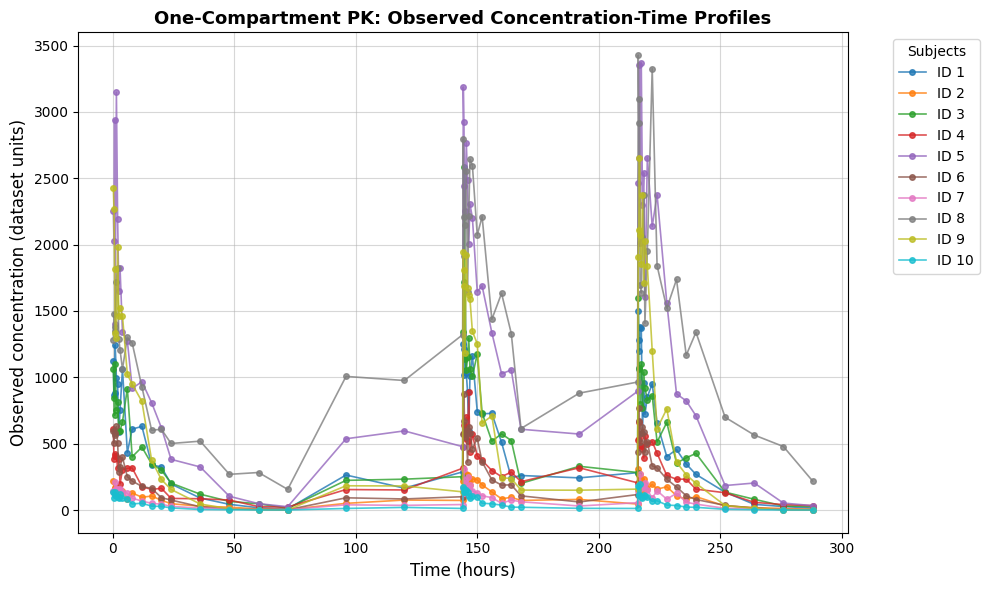

In [14]:
# ==================================================
#SIMULATION 1: OBSERVED PK CONCENTRATION-TIME PROFILES
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select observation records
# EVID = 0 indicates observations
# MDV = 0 indicates usable concentration measurements

pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0)
].copy()

# Remove invalid concentrations
pk_obs = pk_obs[
    (pk_obs["DV"] > 0) &
    (pk_obs["TIME"] >= 0)
]

# Select the first 10 subjects
subjects = sorted(pk_obs["ID"].unique())[:10]

plt.figure(figsize=(10, 6))

for subject in subjects:

    data = pk_obs[pk_obs["ID"] == subject]

    plt.plot(
        data["TIME"],
        data["DV"],
        marker="o",
        markersize=4,
        linewidth=1.2,
        alpha=0.8,
        label=f"ID {subject}"
    )

plt.xlabel("Time (hours)", fontsize=12)
plt.ylabel("Observed concentration (dataset units)", fontsize=12)

plt.title(
    "One-Compartment PK: Observed Concentration-Time Profiles",
    fontsize=13,
    fontweight="bold"
)

plt.legend(
    title="Subjects",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.5)
plt.tight_layout()

plt.savefig(
    "Observed_PK_Profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Total subjects: 120
Total observations: 6951


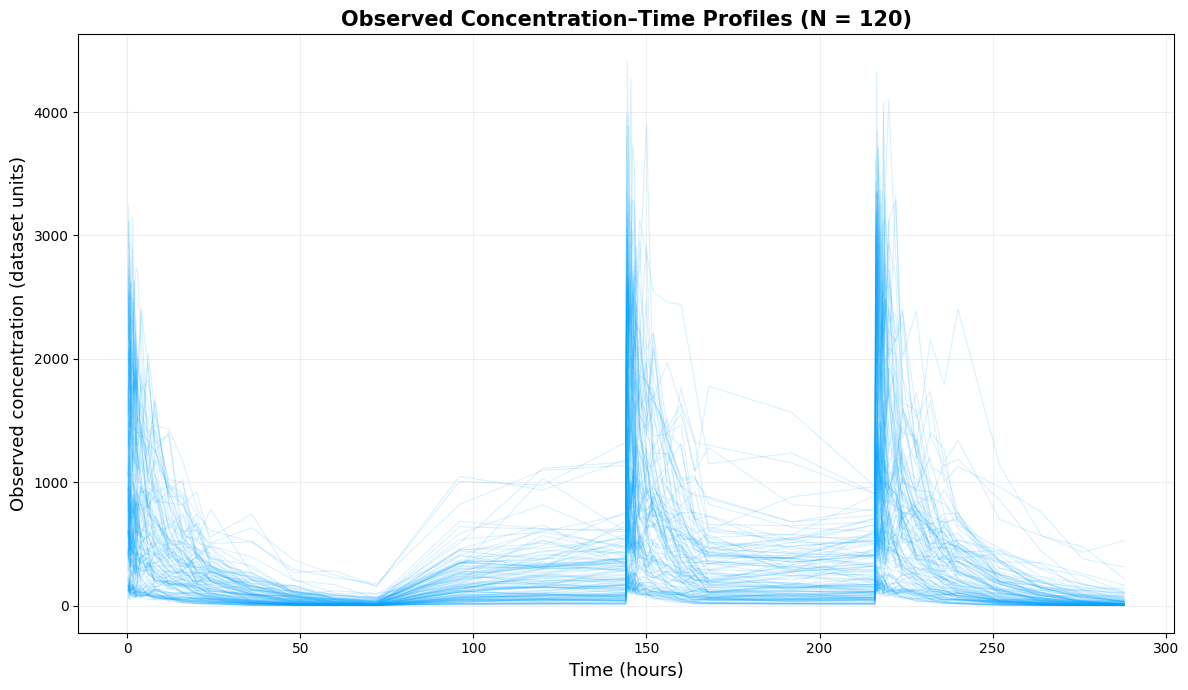

In [15]:
# ==========================================================
# PROJECT 1: ONE-COMPARTMENT PK MODEL
# FIGURE 1: OBSERVED CONCENTRATIONS FOR ALL 120 SUBJECTS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Select valid observation records
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"] > 0)
].copy()

# Identify all subjects
subjects = sorted(pk_obs["ID"].unique())

print("Total subjects:", len(subjects))
print("Total observations:", len(pk_obs))

# Create the plot
plt.figure(figsize=(12, 7))

for subject in subjects:

    data = pk_obs[pk_obs["ID"] == subject]
    data = data.sort_values("TIME")

    plt.plot(
        data["TIME"],
        data["DV"],
        color="#00A3FF",
        linewidth=0.8,
        alpha=0.15
    )

plt.xlabel("Time (hours)", fontsize=13)
plt.ylabel("Observed concentration (dataset units)", fontsize=13)

plt.title(
    "Observed Concentration–Time Profiles (N = 120)",
    fontsize=15,
    fontweight="bold"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "PK_120_Subjects.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Total subjects: 120
Total observations: 6951


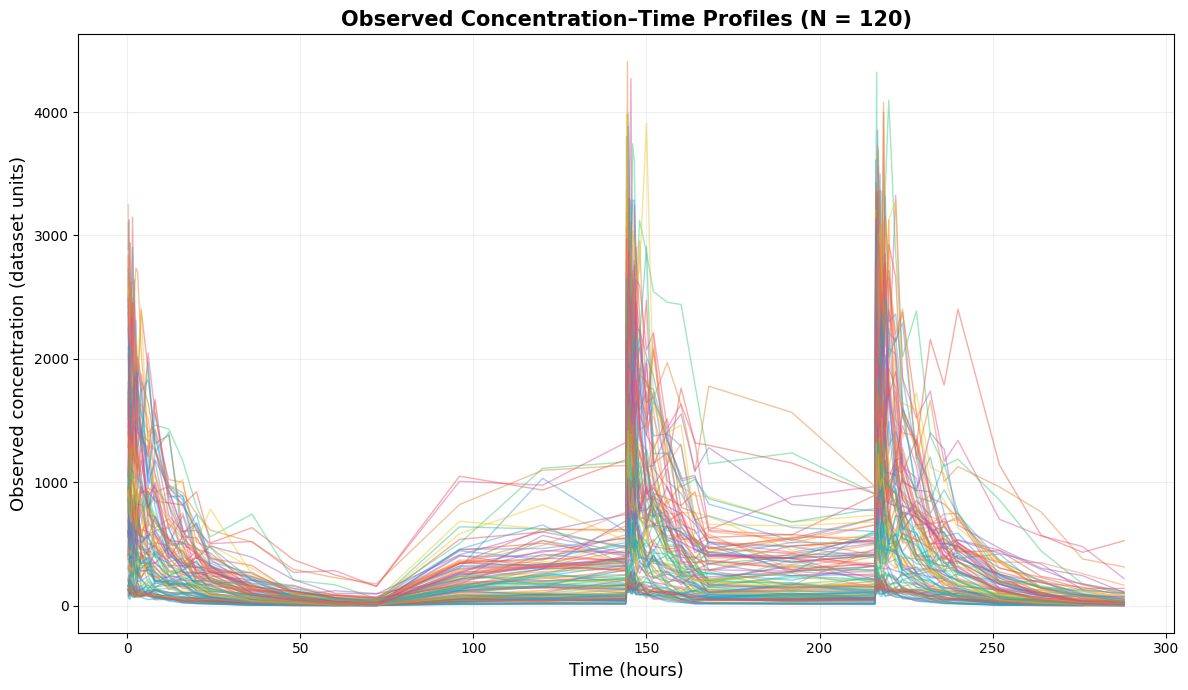

In [16]:
# ==========================================================
# PROJECT 1: ONE-COMPARTMENT PK MODEL
# FIGURE 1: MULTICOLORED PK PROFILES FOR 120 SUBJECTS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Select observation records
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"] > 0)
].copy()

# Identify all subjects
subjects = sorted(pk_obs["ID"].unique())

print("Total subjects:", len(subjects))
print("Total observations:", len(pk_obs))

# Define colors
colors = [
    "#00A3FF",  # Bright blue
    "#FF7F50",  # Coral orange
    "#2ECC71",  # Green
    "#9B59B6",  # Purple
    "#E74C3C",  # Red
    "#F1C40F",  # Yellow
    "#1ABC9C",  # Turquoise
    "#E84393",  # Pink
    "#3498DB",  # Blue
    "#E67E22"   # Orange
]

# Create figure
plt.figure(figsize=(12, 7))

# Plot all 120 subjects
for i, subject in enumerate(subjects):

    data = pk_obs[pk_obs["ID"] == subject]
    data = data.sort_values("TIME")

    plt.plot(
        data["TIME"],
        data["DV"],
        color=colors[i % len(colors)],
        linewidth=1.0,
        alpha=0.45
    )

# Figure formatting
plt.xlabel("Time (hours)", fontsize=13)

plt.ylabel(
    "Observed concentration (dataset units)",
    fontsize=13
)

plt.title(
    "Observed Concentration–Time Profiles (N = 120)",
    fontsize=15,
    fontweight="bold"
)

plt.grid(alpha=0.2)

plt.tight_layout()

# Save figure
plt.savefig(
    "PK_120_Subjects_Multicolor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Total subjects: 120
Total observations: 6951


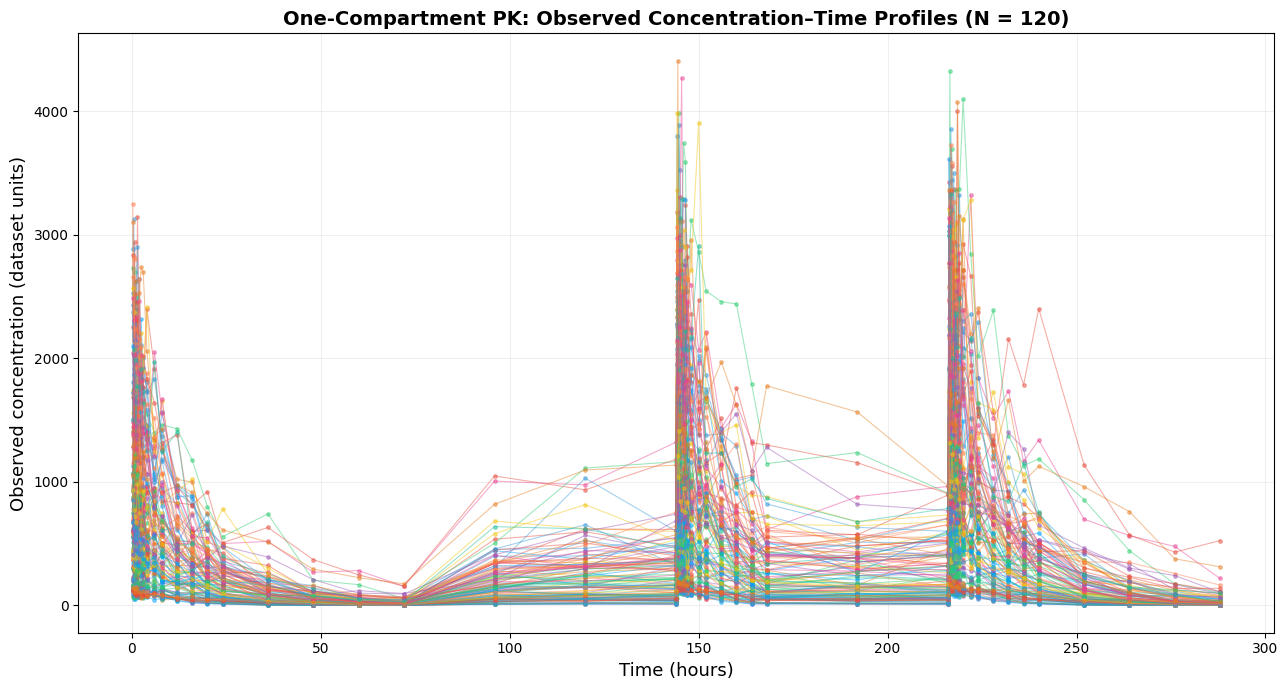

In [17]:
# ==========================================================
# PROJECT 1: ONE-COMPARTMENT PK MODEL
# FIGURE: OBSERVED PK PROFILES WITH DATA POINTS (N = 120)
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# STEP 1: Select valid observation records
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"] > 0)
].copy()

# STEP 2: Identify all subjects
subjects = sorted(pk_obs["ID"].unique())

print("Total subjects:", len(subjects))
print("Total observations:", len(pk_obs))

# STEP 3: Define colors
colors = [
    "#00A3FF",  # Bright blue
    "#FF7F50",  # Coral orange
    "#2ECC71",  # Green
    "#9B59B6",  # Purple
    "#E74C3C",  # Red
    "#F1C40F",  # Yellow
    "#1ABC9C",  # Turquoise
    "#E84393",  # Pink
    "#3498DB",  # Blue
    "#E67E22"   # Orange
]

# STEP 4: Create figure
plt.figure(figsize=(13, 7))

# STEP 5: Plot all subjects with observation points
for i, subject in enumerate(subjects):

    data = pk_obs[pk_obs["ID"] == subject]
    data = data.sort_values("TIME")

    plt.plot(
        data["TIME"],
        data["DV"],
        color=colors[i % len(colors)],
        marker="o",          # Add observation circles
        markersize=2.5,      # Small circles
        linewidth=0.8,
        alpha=0.45
    )

# STEP 6: Format figure
plt.xlabel("Time (hours)", fontsize=13)

plt.ylabel(
    "Observed concentration (dataset units)",
    fontsize=13
)

plt.title(
    "One-Compartment PK: Observed Concentration–Time Profiles (N = 120)",
    fontsize=14,
    fontweight="bold"
)

plt.grid(alpha=0.2)
plt.tight_layout()

# STEP 7: Save figure
plt.savefig(
    "PK_120_Subjects_With_Observations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

AI STRIKER - ONE-COMPARTMENT SIMULATION
--------------------------------------
Clearance (CL): 4.07 L/h
Volume (V): 65.14 L
Elimination rate constant: 0.0625 h^-1
Elimination half-life: 11.09 hours


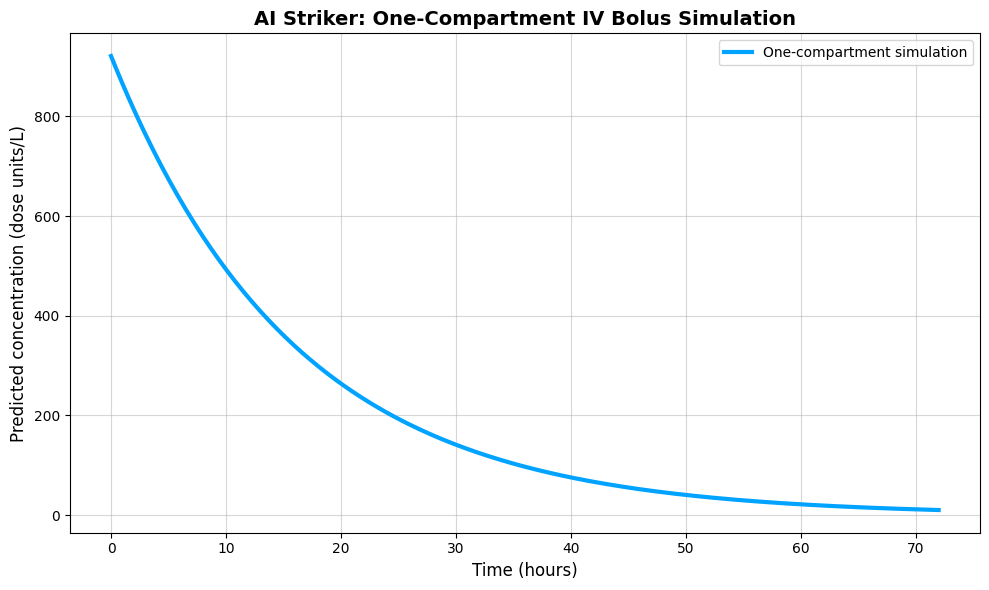

In [18]:
# ==================================================
# SIMULATION 2: ONE-COMPARTMENT IV BOLUS PK MODEL
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# Extract PK parameters for subject 1
subject1 = pk1[pk1["ID"] == 1]

CL = subject1["CL"].iloc[0]
V = subject1["V"].iloc[0]

# Hypothetical IV bolus dose
DOSE = 60000

# Elimination rate constant
ke = CL / V

# Elimination half-life
half_life = np.log(2) / ke

# Simulation time
time = np.linspace(0, 72, 300)

# One-compartment model
concentration = (DOSE / V) * np.exp(-ke * time)

# Display estimated PK parameters
print("AI STRIKER - ONE-COMPARTMENT SIMULATION")
print("--------------------------------------")

print(f"Clearance (CL): {CL:.2f} L/h")
print(f"Volume (V): {V:.2f} L")
print(f"Elimination rate constant: {ke:.4f} h^-1")
print(f"Elimination half-life: {half_life:.2f} hours")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    time,
    concentration,
    color="#00A3FF",
    linewidth=3,
    label="One-compartment simulation"
)

plt.xlabel("Time (hours)", fontsize=12)
plt.ylabel("Predicted concentration (dose units/L)", fontsize=12)

plt.title(
    "AI Striker: One-Compartment IV Bolus Simulation",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.5)
plt.tight_layout()

plt.savefig(
    "One_Compartment_Simulation.png",
    dpi=300
)

plt.show()

AI STRIKER: LAST PLASMA SAMPLING ANALYSIS
----------------------------------------
Number of subjects: 120
Latest sampling time: 288.0 hours
Earliest final sampling time: 276.0 hours


,ID,Last_Sampling_Time,Number_of_Samples,Last_Sampling_Day
0,1,288.0,58,12.0
1,2,288.0,58,12.0
2,3,288.0,58,12.0
3,4,288.0,58,12.0
4,5,288.0,58,12.0
5,6,288.0,58,12.0
6,7,288.0,58,12.0
7,8,288.0,58,12.0
8,9,288.0,58,12.0
9,10,288.0,58,12.0


,Last_Sampling_Time
count,120.00000
mean,287.50000
std,2.40797
min,276.00000
25%,288.00000
50%,288.00000
75%,288.00000
max,288.00000


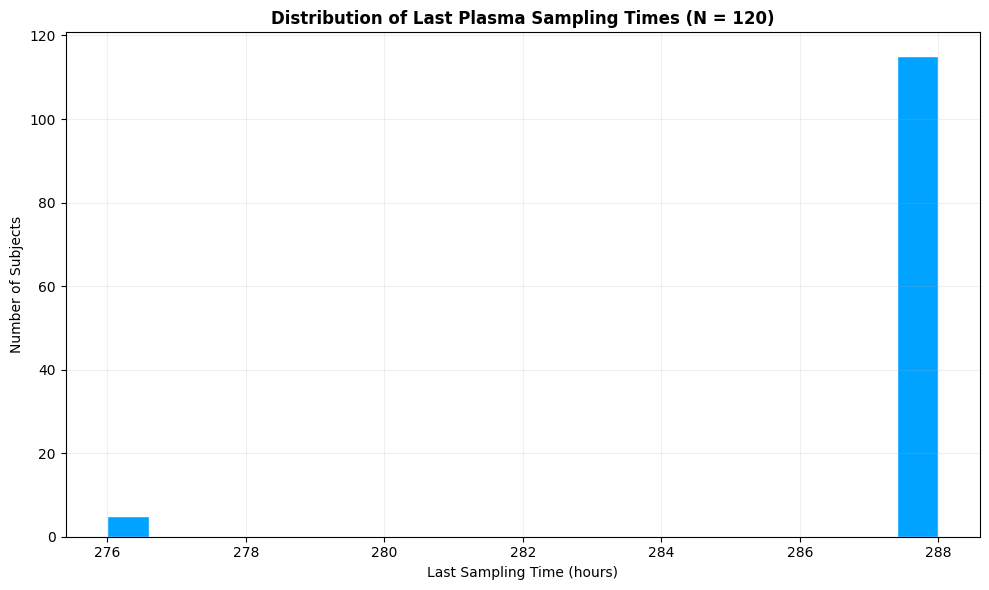

In [19]:
# ==========================================================
# ANALYSIS 1: LAST PLASMA SAMPLING TIME
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Select valid plasma concentration observations
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"].notna())
].copy()

# Identify the final sampling time for each subject
last_sample = (
    pk_obs.groupby("ID", as_index=False)
    .agg(
        Last_Sampling_Time=("TIME", "max"),
        Number_of_Samples=("DV", "count")
    )
)

# Convert hours to days
last_sample["Last_Sampling_Day"] = (
    last_sample["Last_Sampling_Time"] / 24
)

# Display results
print("AI STRIKER: LAST PLASMA SAMPLING ANALYSIS")
print("----------------------------------------")

print("Number of subjects:", len(last_sample))

print(
    "Latest sampling time:",
    last_sample["Last_Sampling_Time"].max(),
    "hours"
)

print(
    "Earliest final sampling time:",
    last_sample["Last_Sampling_Time"].min(),
    "hours"
)

display(last_sample.head(20))

# Summary statistics
display(last_sample["Last_Sampling_Time"].describe())

# Plot distribution
plt.figure(figsize=(10, 6))

plt.hist(
    last_sample["Last_Sampling_Time"],
    bins=20,
    color="#00A3FF",
    edgecolor="white"
)

plt.xlabel("Last Sampling Time (hours)")
plt.ylabel("Number of Subjects")

plt.title(
    "Distribution of Last Plasma Sampling Times (N = 120)",
    fontweight="bold"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Last_Sampling_Time.png",
    dpi=300
)

plt.show()

In [12]:
# ==================================================
# ANALYSIS 1: FINAL PLASMA SAMPLING TIME
# ==================================================

import pandas as pd

# Select actual plasma observations
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"].notna())
].copy()

# Determine final sampling time for each subject
last_sample = (
    pk_obs.groupby("ID")["TIME"]
    .max()
    .reset_index()
)

last_sample.columns = ["ID", "Last_Sampling_Time"]

# Convert hours to days
last_sample["Last_Sampling_Day"] = (
    last_sample["Last_Sampling_Time"] / 24
)

# Summarize final sampling times
summary = (
    last_sample.groupby(
        ["Last_Sampling_Time", "Last_Sampling_Day"]
    )
    .size()
    .reset_index(name="Number_of_Subjects")
)

summary["Percentage"] = (
    summary["Number_of_Subjects"] /
    len(last_sample) * 100
).round(2)

print("FINAL PLASMA SAMPLING SUMMARY")
display(summary)

print(
    "\nLatest plasma sampling time:",
    last_sample["Last_Sampling_Time"].max(),
    "hours"
)

print(
    "Latest plasma sampling day:",
    last_sample["Last_Sampling_Day"].max()
)

FINAL PLASMA SAMPLING SUMMARY


,Last_Sampling_Time,Last_Sampling_Day,Number_of_Subjects,Percentage
0,276.0,11.5,5,4.17
1,288.0,12.0,115,95.83



Latest plasma sampling time: 288.0 hours
Latest plasma sampling day: 12.0


AI STRIKER: TARGET ATTAINMENT ANALYSIS
-------------------------------------
Hypothetical target: 500
Observations above target: 40.84%


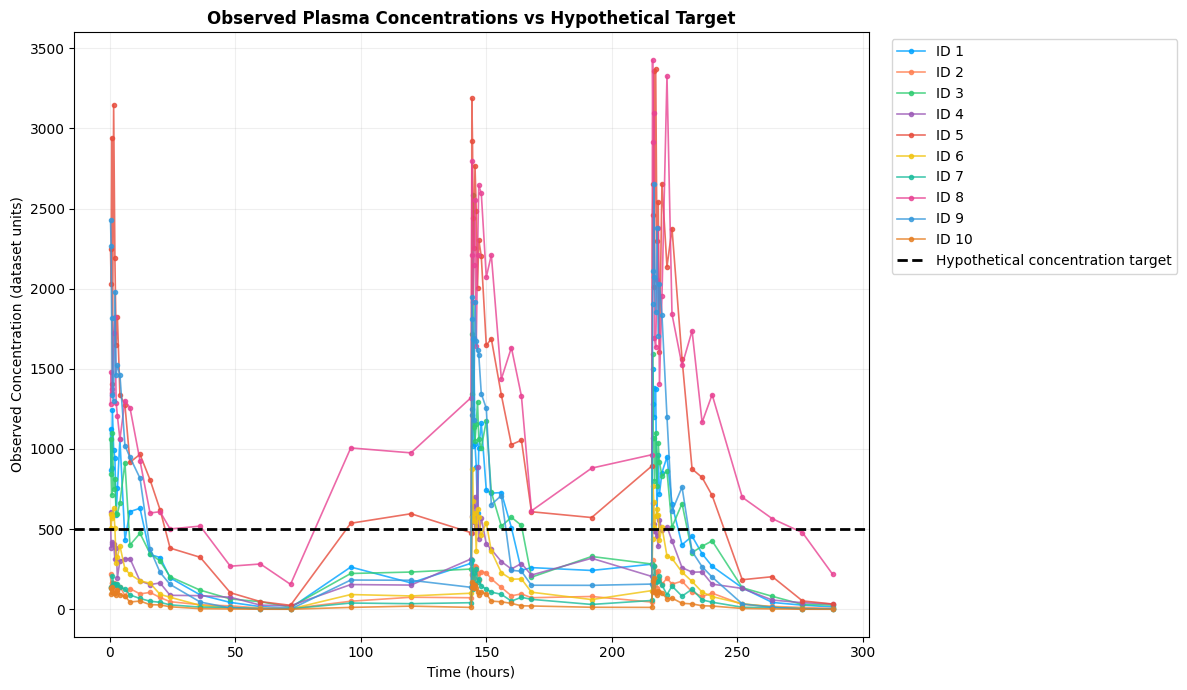

In [20]:
# ==========================================================
# ANALYSIS 2: OBSERVED CONCENTRATIONS VS TARGET
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hypothetical concentration target
TARGET = 500

# Select valid observations
pk_obs = pk1[
    (pk1["EVID"] == 0) &
    (pk1["MDV"] == 0) &
    (pk1["DV"].notna()) &
    (pk1["TIME"] >= 0)
].copy()

# Determine whether each observation meets the target
pk_obs["Target_Attained"] = (
    pk_obs["DV"] >= TARGET
).astype(int)

# Overall percentage of observation records above target
overall_attainment = (
    pk_obs["Target_Attained"].mean() * 100
)

print("AI STRIKER: TARGET ATTAINMENT ANALYSIS")
print("-------------------------------------")

print(f"Hypothetical target: {TARGET}")
print(
    f"Observations above target: "
    f"{overall_attainment:.2f}%"
)

# Plot observations for the first 10 subjects
subjects = sorted(pk_obs["ID"].unique())[:10]

colors = [
    "#00A3FF",
    "#FF7F50",
    "#2ECC71",
    "#9B59B6",
    "#E74C3C",
    "#F1C40F",
    "#1ABC9C",
    "#E84393",
    "#3498DB",
    "#E67E22"
]

plt.figure(figsize=(12, 7))

for i, subject in enumerate(subjects):

    data = pk_obs[
        pk_obs["ID"] == subject
    ].sort_values("TIME")

    plt.plot(
        data["TIME"],
        data["DV"],
        color=colors[i],
        marker="o",
        markersize=3,
        linewidth=1.2,
        alpha=0.8,
        label=f"ID {subject}"
    )

# Add target line
plt.axhline(
    y=TARGET,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Hypothetical concentration target"
)

plt.xlabel("Time (hours)")
plt.ylabel("Observed Concentration (dataset units)")

plt.title(
    "Observed Plasma Concentrations vs Hypothetical Target",
    fontweight="bold"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Observed_Target_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Original subjects: 120
Virtual subjects generated: 10000

Reference dosing schedule:


,TIME,AMT
0,0.0,60000
20,72.0,60000
22,96.0,60000
24,120.0,60000
26,144.0,60000
42,168.0,60000
44,192.0,60000
46,216.0,60000



Monte Carlo simulation completed!


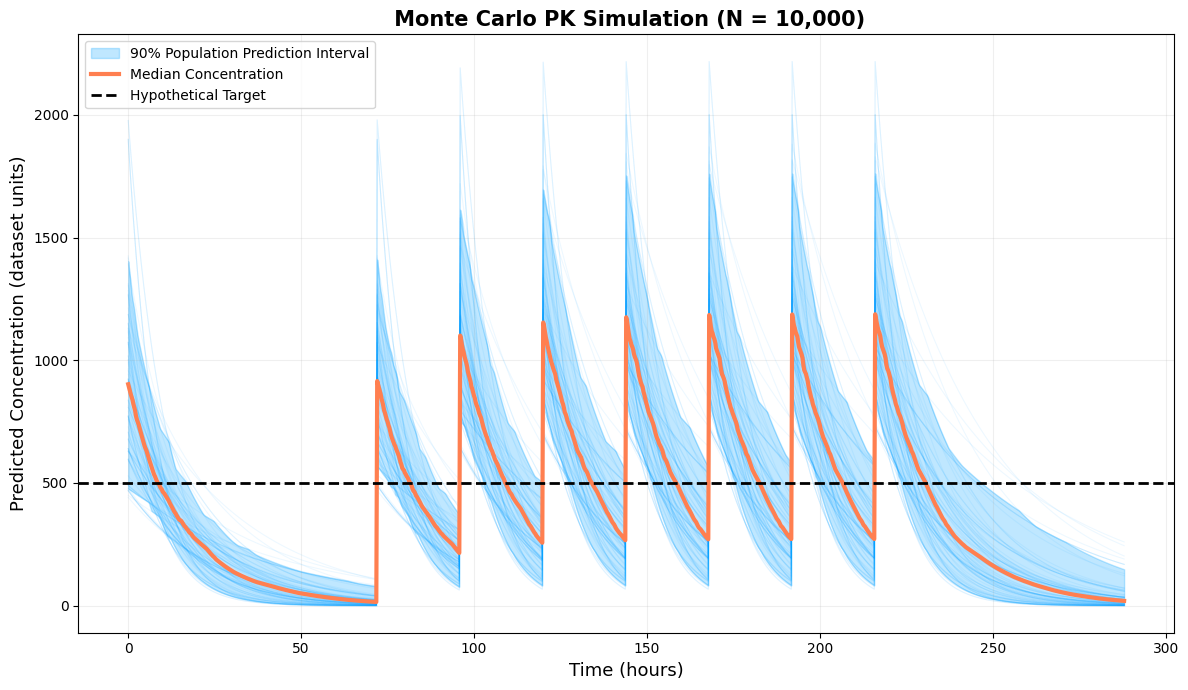


FINAL PLASMA CONCENTRATION AT 288 HOURS
---------------------------------------
Median: 19.04
5th percentile: 0.39
95th percentile: 147.93

TARGET ATTAINMENT AT 288 HOURS
--------------------------------
Target: 500
Subjects meeting target: 0
Target attainment: 0.00%


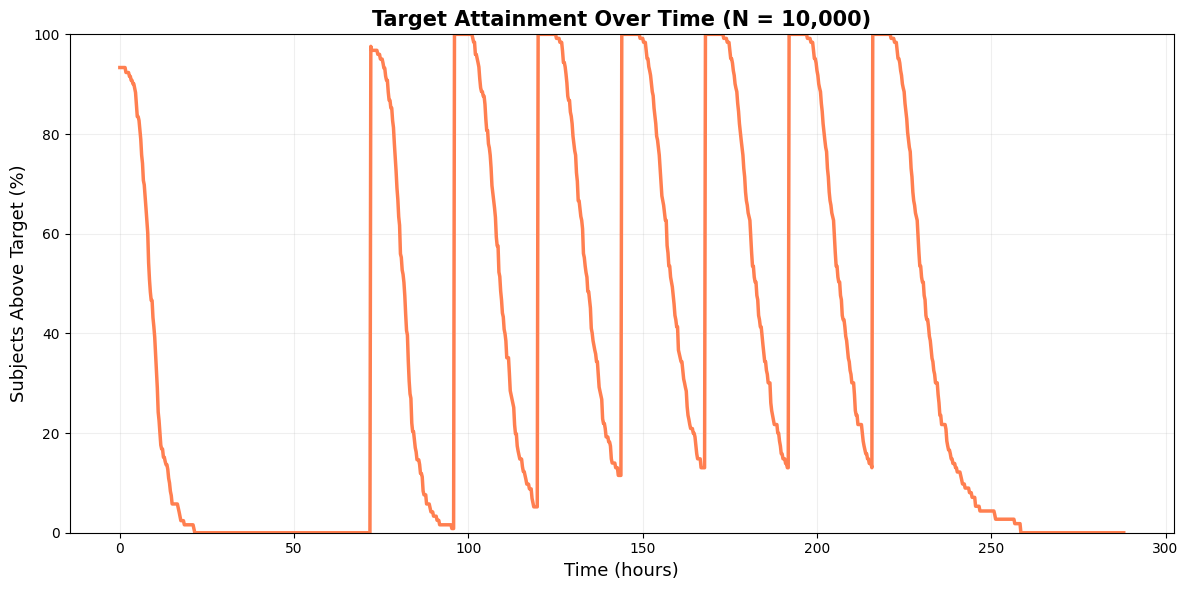


Simulation results saved successfully!


In [22]:
# ============================================================
# MONTE CARLO SIMULATION: 10,000 VIRTUAL SUBJECTS
# ONE-COMPARTMENT IV BOLUS PK MODEL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# STEP 1: SIMULATION SETTINGS
# ------------------------------------------------------------

N_SIM = 10000
SIM_END = 288
TARGET = 500
SEED = 2026

rng = np.random.default_rng(SEED)

# Simulation time grid (every 0.25 hours)
time = np.arange(0, SIM_END + 0.25, 0.25)

# ------------------------------------------------------------
# STEP 2: EXTRACT PK PARAMETERS FROM ORIGINAL DATASET
# ------------------------------------------------------------

# One CL and V value per original subject
original_subjects = (
    pk1.groupby("ID")[["CL", "V"]]
    .first()
    .reset_index()
)

# Remove invalid parameter values
original_subjects = original_subjects[
    (original_subjects["CL"] > 0) &
    (original_subjects["V"] > 0)
].copy()

print("Original subjects:", len(original_subjects))

# ------------------------------------------------------------
# STEP 3: GENERATE 10,000 VIRTUAL SUBJECTS
# ------------------------------------------------------------

# Bootstrap resampling preserves the observed CL-V relationship
sample_indices = rng.choice(
    len(original_subjects),
    size=N_SIM,
    replace=True
)

virtual_population = original_subjects.iloc[
    sample_indices
].copy().reset_index(drop=True)

virtual_population["Virtual_ID"] = np.arange(
    1, N_SIM + 1
)

CL_sim = virtual_population["CL"].to_numpy()
V_sim = virtual_population["V"].to_numpy()

KE_sim = CL_sim / V_sim

print("Virtual subjects generated:", len(virtual_population))

# ------------------------------------------------------------
# STEP 4: EXTRACT DOSING HISTORY
# ------------------------------------------------------------

# Use subject 1 as the reference dosing regimen.
# EVID=1 indicates dosing events.
dose_data = pk1[
    (pk1["ID"] == 1) &
    (pk1["EVID"] == 1) &
    (pk1["AMT"] > 0)
][["TIME", "AMT"]].sort_values("TIME")

print("\nReference dosing schedule:")
display(dose_data)

dose_times = dose_data["TIME"].to_numpy()
dose_amounts = dose_data["AMT"].to_numpy()

# ------------------------------------------------------------
# STEP 5: SIMULATE CONCENTRATION-TIME PROFILES
# ------------------------------------------------------------

# Matrix dimensions:
# 10,000 subjects x 1,153 time points

concentrations = np.zeros(
    (N_SIM, len(time)),
    dtype=np.float64
)

# Multiple-dose IV bolus simulation
for dose_time, dose_amount in zip(
    dose_times,
    dose_amounts
):

    mask = time >= dose_time

    elapsed_time = time[mask] - dose_time

    concentrations[:, mask] += (
        dose_amount / V_sim[:, None]
    ) * np.exp(
        -KE_sim[:, None] * elapsed_time[None, :]
    )

print("\nMonte Carlo simulation completed!")

# ------------------------------------------------------------
# STEP 6: CALCULATE POPULATION PREDICTION INTERVALS
# ------------------------------------------------------------

median_conc = np.percentile(
    concentrations, 50, axis=0
)

lower_90 = np.percentile(
    concentrations, 5, axis=0
)

upper_90 = np.percentile(
    concentrations, 95, axis=0
)

# ------------------------------------------------------------
# STEP 7: PLOT POPULATION CONCENTRATION-TIME PROFILES
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

# Display 100 randomly selected individual profiles
selected = rng.choice(
    N_SIM,
    size=100,
    replace=False
)

for i in selected:
    plt.plot(
        time,
        concentrations[i],
        color="#00A3FF",
        alpha=0.07,
        linewidth=0.8
    )

# 90% population interval
plt.fill_between(
    time,
    lower_90,
    upper_90,
    color="#00A3FF",
    alpha=0.25,
    label="90% Population Prediction Interval"
)

# Median profile
plt.plot(
    time,
    median_conc,
    color="#FF7F50",
    linewidth=3,
    label="Median Concentration"
)

# Hypothetical target
plt.axhline(
    TARGET,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Hypothetical Target"
)

plt.xlabel("Time (hours)", fontsize=13)
plt.ylabel("Predicted Concentration (dataset units)", fontsize=13)

plt.title(
    " Monte Carlo PK Simulation (N = 10,000)",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Monte_Carlo_10000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# STEP 8: FINAL CONCENTRATION AT 288 HOURS
# ------------------------------------------------------------

final_concentration = concentrations[:, -1]

print("\nFINAL PLASMA CONCENTRATION AT 288 HOURS")
print("---------------------------------------")

print(
    f"Median: {np.median(final_concentration):.2f}"
)

print(
    f"5th percentile: {np.percentile(final_concentration, 5):.2f}"
)

print(
    f"95th percentile: {np.percentile(final_concentration, 95):.2f}"
)

# ------------------------------------------------------------
# STEP 9: TARGET ATTAINMENT AT 288 HOURS
# ------------------------------------------------------------

attained = final_concentration >= TARGET

pta_final = attained.mean() * 100

print("\nTARGET ATTAINMENT AT 288 HOURS")
print("--------------------------------")

print(f"Target: {TARGET}")
print(f"Subjects meeting target: {attained.sum()}")
print(f"Target attainment: {pta_final:.2f}%")

# ------------------------------------------------------------
# STEP 10: PLOT TARGET ATTAINMENT OVER TIME
# ------------------------------------------------------------

pta_time = (
    concentrations >= TARGET
).mean(axis=0) * 100

plt.figure(figsize=(12, 6))

plt.plot(
    time,
    pta_time,
    color="#FF7F50",
    linewidth=2.5
)

plt.xlabel("Time (hours)", fontsize=13)
plt.ylabel("Subjects Above Target (%)", fontsize=13)

plt.title(
    "Target Attainment Over Time (N = 10,000)",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0, 100)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "AI_Striker_PTA_10000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# STEP 11: EXPORT SIMULATION SUMMARY
# ------------------------------------------------------------

simulation_summary = pd.DataFrame({
    "TIME": time,
    "Median_Concentration": median_conc,
    "P05_Concentration": lower_90,
    "P95_Concentration": upper_90,
    "Target_Attainment_Percent": pta_time
})

simulation_summary.to_csv(
    "AI_Striker_Monte_Carlo_Summary.csv",
    index=False
)

virtual_population[
    ["Virtual_ID", "CL", "V"]
].to_csv(
    "AI_Striker_Virtual_Population.csv",
    index=False
)

print("\nSimulation results saved successfully!")

# New Section

# New Section